In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import folium
from folium.plugins import MarkerCluster

In [2]:
# chemin absolu du répertoire du script
BASE_DIR = os.path.dirname(os.path.abspath("velib-data-analysis"))

# chemin relatif du fichier CSV
FILENAME = os.path.join(BASE_DIR, "..", "data", "velib_data.csv")

In [3]:
# les données

df = pd.read_csv(FILENAME)

In [4]:
# Convertir la colonne 'timestamp' en datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Trier les données par timestamp
df = df.sort_values('timestamp')

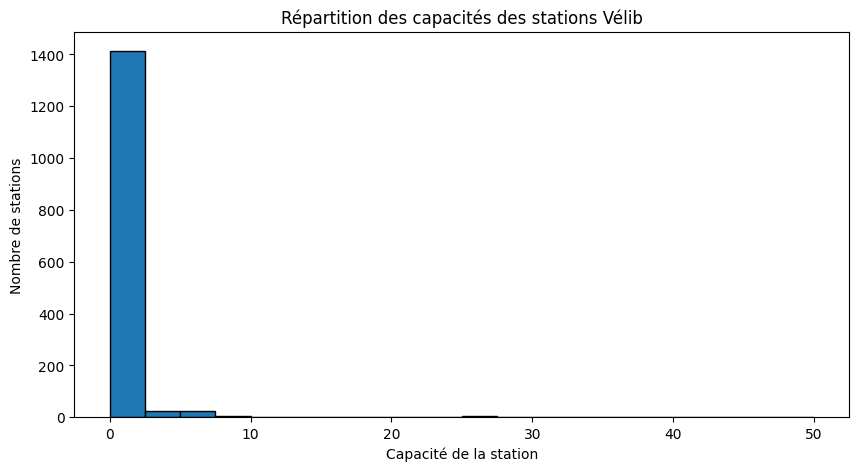

In [5]:
# Histogramme des capacités des stations
plt.figure(figsize=(10, 5))
plt.hist(df['capacite'], bins=20, edgecolor='black')
plt.xlabel('Capacité de la station')
plt.ylabel('Nombre de stations')
plt.title('Répartition des capacités des stations Vélib')
plt.show()

In [6]:
# Carte interactive des stations
m = folium.Map(location=[48.8566, 2.3522], zoom_start=12)
marker_cluster = MarkerCluster().add_to(m)

for _, row in df.iterrows():
    folium.Marker(
        location=[row['latitude'], row['longitude']],
        popup=f"{row['nom_station']}\nCapacité: {row['capacite']}\nVélos dispo: {row['velos_mecaniques'] + row['velos_electriques']}",
    ).add_to(marker_cluster)

In [7]:
m

In [8]:
# Enregistrer la carte dans un fichier HTML
m.save('velib_stations_map.html')

In [9]:
# Affichage du ratio vélos disponibles/capacité par station
df['ratio_dispo'] = (df['velos_mecaniques'] + df['velos_electriques']) / df['capacite']

# Supprimer les valeurs nulles pour éviter les erreurs dans l'affichage
ratio_dispo_clean = df['ratio_dispo'].dropna()

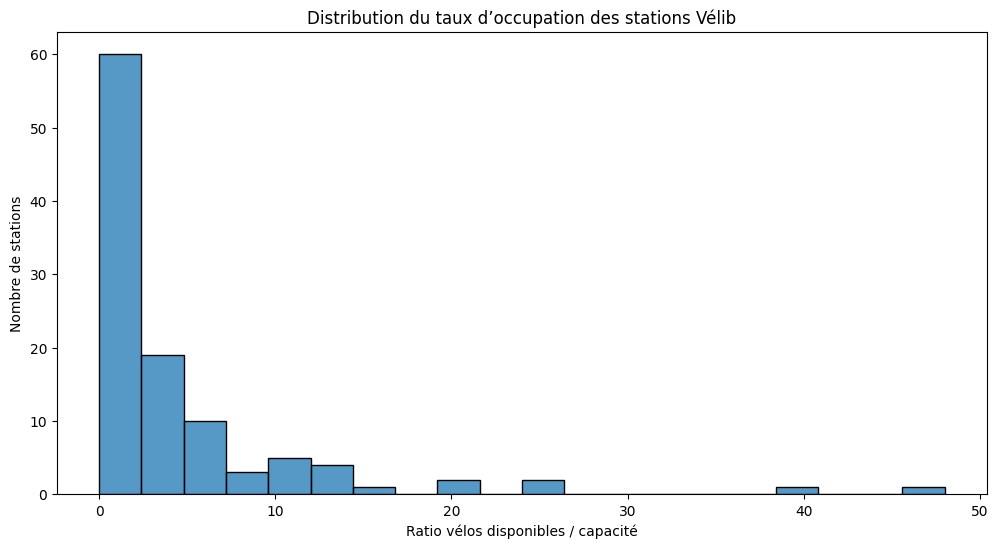

In [10]:
# Affichage du ratio vélos disponibles/capacité par station
df['ratio_dispo'] = (df['velos_mecaniques'] + df['velos_electriques']) / df['capacite']
ratio_dispo_clean = df['ratio_dispo'].replace([np.inf, -np.inf], np.nan).dropna()
plt.figure(figsize=(12, 6))
sns.histplot(ratio_dispo_clean, bins=20, kde=False, edgecolor='black')
plt.xlabel('Ratio vélos disponibles / capacité')
plt.ylabel('Nombre de stations')
plt.title('Distribution du taux d’occupation des stations Vélib')
plt.show()

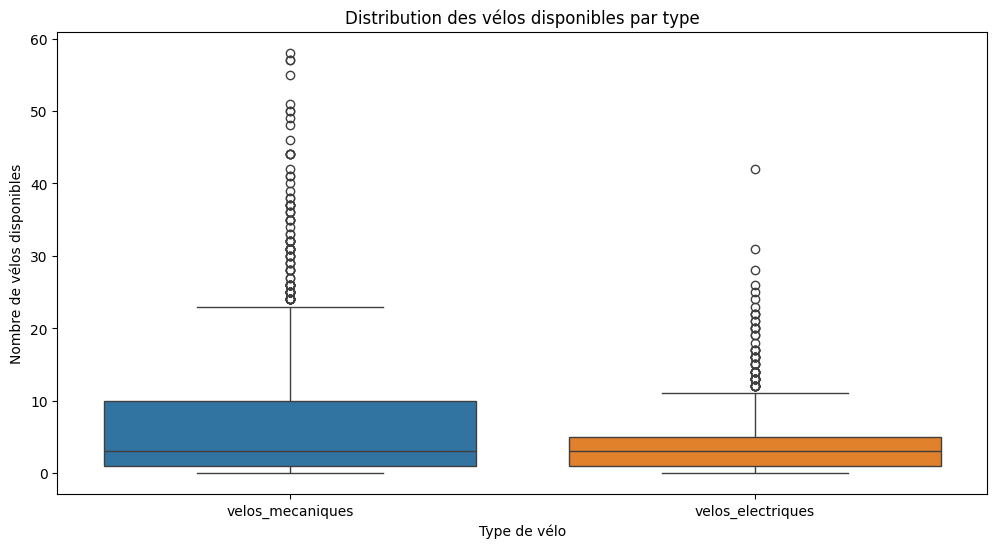

In [11]:
# Boxplot des vélos disponibles par station
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[['velos_mecaniques', 'velos_electriques']])
plt.xlabel('Type de vélo')
plt.ylabel('Nombre de vélos disponibles')
plt.title('Distribution des vélos disponibles par type')
plt.show()

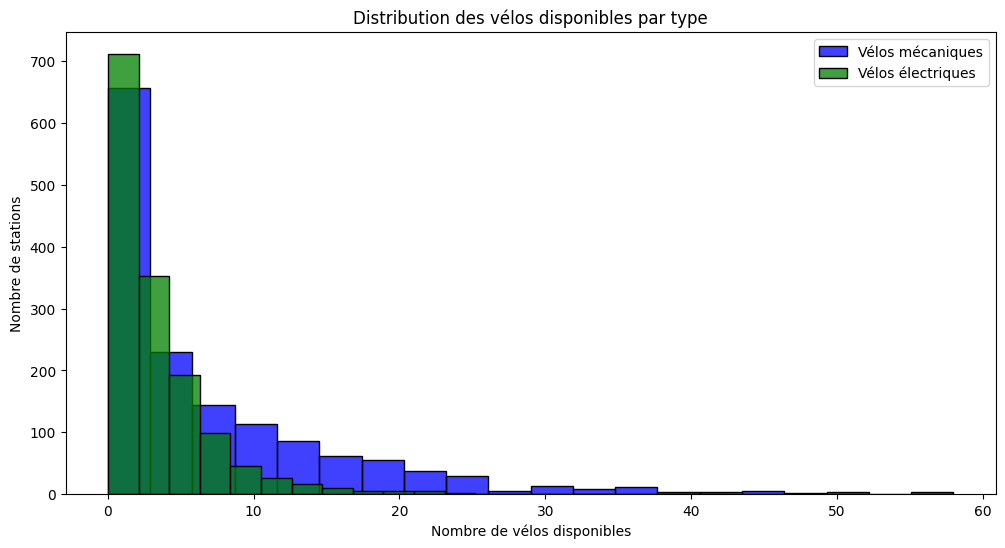

In [12]:
# Histogramme des vélos disponibles par type
plt.figure(figsize=(12, 6))
sns.histplot(df['velos_mecaniques'], bins=20, kde=False, color='blue', label='Vélos mécaniques', edgecolor='black')
sns.histplot(df['velos_electriques'], bins=20, kde=False, color='green', label='Vélos électriques', edgecolor='black')
plt.xlabel('Nombre de vélos disponibles')
plt.ylabel('Nombre de stations')
plt.title('Distribution des vélos disponibles par type')
plt.legend()
plt.show()